# Overview

Here we process output files from Sapiens2 model from json format into workable csv

The steps include:
- 

In [1]:
import os
import glob
import pandas as pd
import numpy

curfolder = os.getcwd()

coordfolder = os.path.join(curfolder, 'Sapiens_Output')
vidfolder = os.path.join(curfolder, 'GTST_sampled')
processedfolder = os.path.join(curfolder, 'Sapiens_Processed')

if not os.path.exists(processedfolder):
    os.makedirs(processedfolder)

vidfiles = glob.glob(os.path.join(vidfolder, '*.mp4'))
coordfiles = glob.glob(os.path.join(coordfolder, '*', '*.json'))

In [2]:
coordsample = coordfiles[0]

# Load in json file
df = pd.read_json(coordsample)
df.head() # Note that it's double-nested

,video,fps,n_frames,frames
pose_out_predictions,GP01_ADLER,50,1,"{'video': 'pose_out', 'image_size': [1080, 192..."


# Pre-Process json to csv

In [3]:
import sys, json, csv, glob, os
import numpy as np

sys.path.append(os.path.join(curfolder, 'Sapiens'))
from keypoints308 import dataset_info
_ki = dataset_info["keypoint_info"]
KP_NAMES = [_ki[i]["name"] for i in range(len(_ki))]
IDX = {KP_NAMES[i]: i for i in range(len(KP_NAMES))}

CONF_THR = 0.6

def unwrap(d):
    fps, video = d.get("fps"), d.get("video")
    node = d["frames"]; pred = None
    if isinstance(node, dict):
        pred = node[next(iter(node))]; video = video or pred.get("video"); node = pred
    if isinstance(node, dict):
        node = node["frames"]
    return node, fps, video, pred

def person_center(inst):
    kp = np.array(inst["keypoints"], float)
    sc = np.array(inst["keypoint_scores"], float)
    good = sc >= CONF_THR
    if good.sum() == 0:
        x1, y1, x2, y2 = inst["bbox"]
        return np.array([(x1 + x2) / 2, (y1 + y2) / 2])
    return kp[good].mean(axis=0)

def person_trunk_size(inst):
    """Shoulder->hip height; falls back to shoulder width if hips aren't confident."""
    kp = np.array(inst["keypoints"], float)
    sc = np.array(inst["keypoint_scores"], float)
    good = sc >= CONF_THR
    def pt(name):
        i = IDX[name]; return kp[i] if good[i] else None
    ls, rs = pt("left_shoulder"), pt("right_shoulder")
    lh, rh = pt("left_hip"), pt("right_hip")
    if ls is not None and rs is not None and lh is not None and rh is not None:
        return np.linalg.norm((lh + rh) / 2 - (ls + rs) / 2)   # trunk height
    if ls is not None and rs is not None:
        return np.linalg.norm(ls - rs)                          # fallback: shoulder width
    return 0.0

def person_score(inst, cx, cy):
    """Lower = more central AND larger (nearer). inf if no usable trunk."""
    c = person_center(inst)
    dist = np.hypot(c[0] - cx, c[1] - cy)
    trunk = person_trunk_size(inst)
    if trunk <= 0:
        return np.inf
    return dist / trunk

def order_by_center_and_trunk(instances, cx, cy):
    return sorted(instances, key=lambda i: person_score(i, cx, cy))

def json_to_wide_csv(json_path, csv_path):
    with open(json_path) as f:
        d = json.load(f)
    frames, fps, video, pred = unwrap(d)

    H, W = pred["image_size"]
    cx, cy = W / 2, H / 2

    n_persons = max((len(fr["instances"]) for fr in frames), default=1)
    header = ["video", "frame", "time_s"]
    for p in range(1, n_persons + 1):
        for nm in KP_NAMES:
            header += [f"p{p}_{nm}_x", f"p{p}_{nm}_y", f"p{p}_{nm}_conf"]

    with open(csv_path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(header)
        for fr in frames:
            idx = int(os.path.splitext(fr["image_name"])[0])
            row = {"video": video, "frame": idx, "time_s": idx / fps if fps else ""}
            insts = order_by_center_and_trunk(fr["instances"], cx, cy)
            for p, inst in enumerate(insts, 1):
                for nm, (x, y), s in zip(KP_NAMES, inst["keypoints"], inst["keypoint_scores"]):
                    row[f"p{p}_{nm}_x"] = x
                    row[f"p{p}_{nm}_y"] = y
                    row[f"p{p}_{nm}_conf"] = s
            w.writerow([row.get(c, "") for c in header])
    return n_persons

json_err = []
for jp in coordfiles:
    print(jp)
    try:
        n = json_to_wide_csv(jp, jp[:-5] + ".csv")
        print(f"wrote {os.path.basename(jp)[:-5]}.csv  ({n} person(s))")
    except Exception as e:
        json_err.append((jp, e))

f:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ADLER\GP01_ADLER_pose.json
wrote GP01_ADLER_pose.csv  (1 person(s))
f:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ANSTECKEN\GP01_ANSTECKEN_pose.json
wrote GP01_ANSTECKEN_pose.csv  (1 person(s))
f:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BLITZ\GP01_BLITZ_pose.json
wrote GP01_BLITZ_pose.csv  (1 person(s))
f:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BODEN\GP01_BODEN_pose.json
wrote GP01_BODEN_pose.csv  (1 person(s))
f:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BRIEF\GP01_BRIEF_pose.json
wrote GP01_BRIEF_pose.csv  (1 person(s))
f:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BUERO\GP01_BUERO_pose.json
wrote GP01_BUERO_pose.csv  (1 person(s))
f:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ENTSCHULDIGEN\GP01_ENTSCHULDIGEN_pose.json
wrote GP01_ENTSCHULDIGEN_pose.csv  (1 person(s))
f:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_GEIGE\GP01_GEIGE_pose.json
wrote GP01_GEIGE_pose.csv  (1 person(s))
f:\GtST_FLESH_KinTrajectory\Sapiens_

In [4]:
json_err

[('f:\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\GP02_STAUBWISCHEN\\GP02_STAUBWISCHEN_pose.json',
  KeyError('frames')),
 ('f:\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\GP11_FANGEN\\GP11_FANGEN_pose.json',
  KeyError('frames')),
 ('f:\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\GP15_VORHANG\\GP15_VORHANG_pose.json',
  KeyError('frames')),
 ('f:\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\GP17_GRAS\\GP17_GRAS_pose.json',
  KeyError('frames')),
 ('f:\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\GP18_HAHN\\GP18_HAHN_pose.json',
  KeyError('frames')),
 ('f:\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\GP18_SICH SORGEN\\GP18_SICH SORGEN_pose.json',
  KeyError('frames')),
 ('f:\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\IP04_01_VORHANG\\IP04_01_VORHANG_pose.json',
  KeyError('frames')),
 ('f:\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\IP06_01_VORHANG\\IP06_01_VORHANG_pose.json',
  KeyError('frames')),
 ('f:\\GtST_FLESH_KinTrajectory\\Sapiens_Output\\IP10_01_ZERREISSEN\\IP10_01_ZERREISSEN_pose.jso

<Axes: xlabel='frame'>

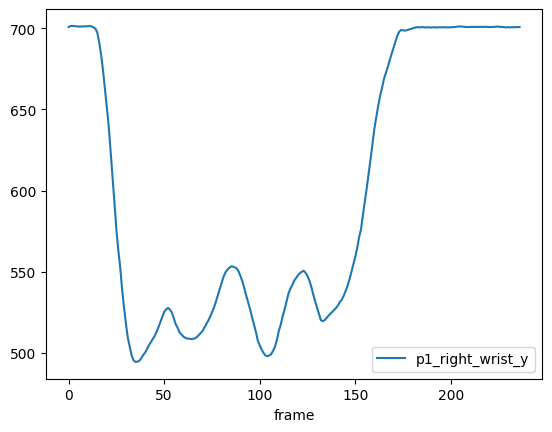

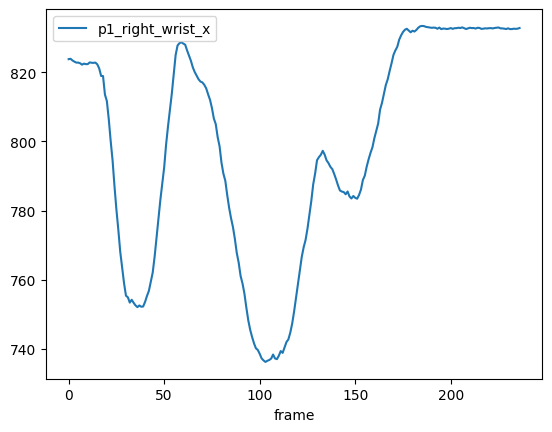

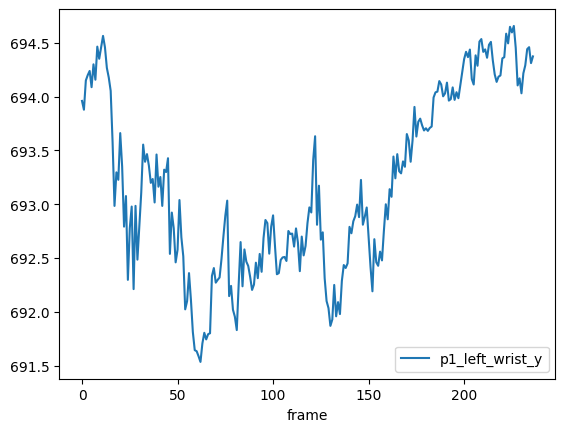

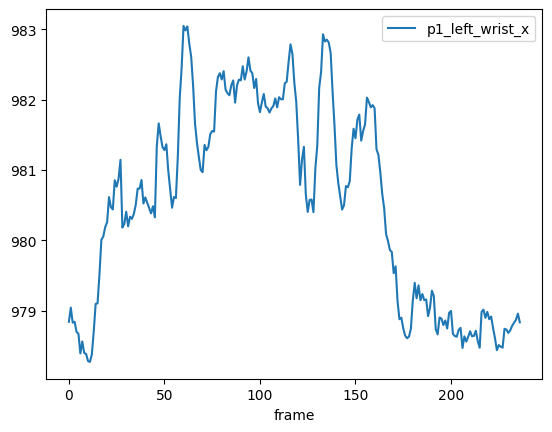

In [5]:
csvfiles = glob.glob(os.path.join(curfolder, 'Sapiens_Output', '*', '*GP01_ANSTECKEN_pose.csv'))
sample_df = pd.read_csv(csvfiles[0])

# plot p1_right_wrist_y
sample_df.plot(x='frame', y='p1_right_wrist_y') # should move once up and once down - notice it's FLIPPED
sample_df.plot(x='frame', y='p1_right_wrist_x') # should slightly move left and right
sample_df.plot(x='frame', y='p1_left_wrist_y') # should not move
sample_df.plot(x='frame', y='p1_left_wrist_x') # should not move




## Check people association (in multi-party frames)

In [ ]:
import numpy as np, cv2, os, glob
import matplotlib.pyplot as plt
import sys

sys.path.append(os.path.join(curfolder, 'Sapiens'))
from keypoints308 import dataset_info

csvfiles = glob.glob(os.path.join(curfolder, 'Sapiens_Output', '*', '*_pose.csv'))

_ki = dataset_info["keypoint_info"]
KP_NAMES = [_ki[i]["name"] for i in range(len(_ki))]
_name2id = {n: i for i, n in enumerate(KP_NAMES)}
SKELETON_EDGES = [(_name2id[a], _name2id[b])
                  for s in dataset_info["skeleton_info"].values()
                  for a, b in [s["link"]]
                  if a in _name2id and b in _name2id]

def person_xy(row, p):
    """Return (308x2 array, 308 conf) for person p from a dataframe row; NaN where missing."""
    xs = np.array([row.get(f"p{p}_{n}_x", np.nan) for n in KP_NAMES], float)
    ys = np.array([row.get(f"p{p}_{n}_y", np.nan) for n in KP_NAMES], float)
    cs = np.array([row.get(f"p{p}_{n}_conf", np.nan) for n in KP_NAMES], float)
    return np.column_stack([xs, ys]), cs

def draw(img, kpts, conf, color, thr=0.3):
    for a, b in SKELETON_EDGES:
        if conf[a] < thr or conf[b] < thr: continue
        if np.isnan(kpts[[a, b]]).any(): continue
        cv2.line(img, tuple(kpts[a].astype(int)), tuple(kpts[b].astype(int)), color, 2)
    for i in range(len(kpts)):
        if conf[i] < thr or np.isnan(kpts[i]).any(): continue
        cv2.circle(img, tuple(kpts[i].astype(int)), 4, color, -1)

for file in csvfiles:
    df = pd.read_csv(file)
    if not any(df.columns.str.contains('p2_')):
        continue
    print('found p2 in', file)

    # frames where BOTH persons have any keypoints -> pick the richest one
    p1_valid = df.filter(regex=r'^p1_.*_conf$').notna().sum(axis=1)
    p2_valid = df.filter(regex=r'^p2_.*_conf$').notna().sum(axis=1)
    both = df[(p1_valid > 0) & (p2_valid > 0)]
    if both.empty:
        print('  no frame has both -> p2 is sporadic; probably safe'); continue
    ridx = (p1_valid + p2_valid).loc[both.index].idxmax()   # most complete frame
    row = df.loc[ridx]
    frame_vis = int(row['frame'])
    print('  showing frame', frame_vis)

    name = os.path.basename(file).split('_pose.csv')[0]
    videofile = glob.glob(os.path.join(curfolder, 'GTST_sampled', name + '*.mp4'))[0]

    cap = cv2.VideoCapture(videofile)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_vis)
    ok, img = cap.read()
    cap.release()
    if not ok:
        print('  could not read frame'); continue

    k1, c1 = person_xy(row, 1)
    k2, c2 = person_xy(row, 2)
    draw(img, k1, c1, (0, 255, 0))     # p1 = green
    draw(img, k2, c2, (0, 0, 255))     # p2 = red

    plt.figure(figsize=(10, 7))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"{name}  frame {frame_vis}   p1=green  p2=red")
    plt.axis('off'); plt.show()
    #break     # remove to step through all p2 files

Now we can see that in only multi-party cases, p1 is the person of interest. We can therefore proceed with keeping only p1_* in the data

# Confidence check

Sapiens2 outputs confidence for each keypoint for each frame. We can create summarization for each keypoint (and participant) to see whether there are some major hick-ups that would favor exclusion of data

In [8]:
csvfiles = glob.glob(os.path.join(curfolder, 'Sapiens_Output', '*', '*_pose.csv'))

TOCHECK = ['nose', 'shoulder', 'elbow', 'hip', 'thumb', 'finger', 'wrist', 'neck']

conf_list = []

for csvfile in csvfiles:
    df = pd.read_csv(csvfile)
    fileID = os.path.basename(csvfile).split('_')[0]
    #print(fileID)
    # keep only columns that contain string from TOCHECK and 'conf'
    df = df[[col for col in df.columns if any([x in col for x in TOCHECK]) and 'conf' in col and 'p1_' in col and '_of_' not in col]]
    
    for c in df.columns:
        conf_list.append([fileID, c, df[c].mean(), df[c].std()])
    
    #break

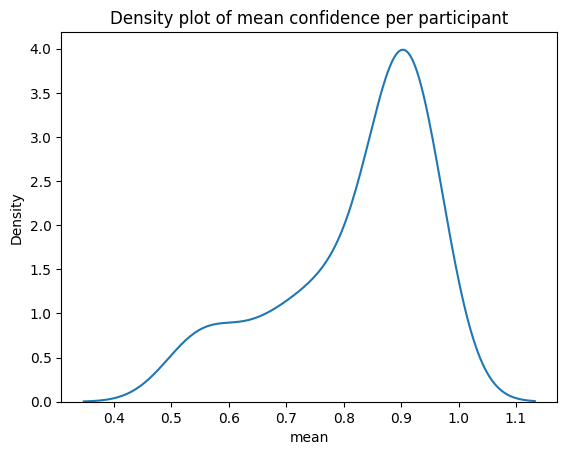

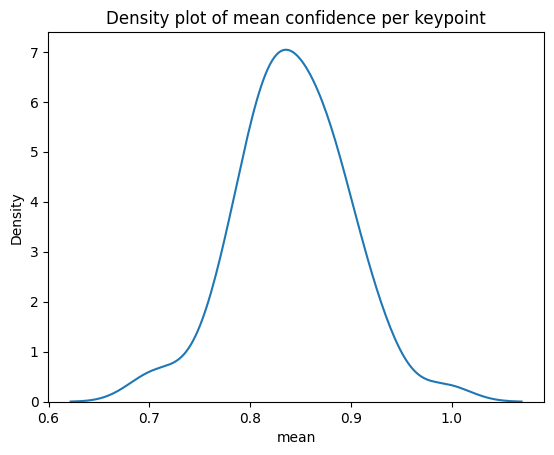

In [9]:
import seaborn as sns

# Calculate mean confidence per participant (fileID)
conf_df = pd.DataFrame(conf_list, columns=['fileID', 'column', 'mean', 'std'])
conf_pcn_mean = conf_df.groupby('fileID')['mean'].mean().reset_index()
conf_kpt_mean = conf_df.groupby('column')['mean'].mean().reset_index()

# Density plot of mean confidence (pcn)
sns.kdeplot(data=conf_pcn_mean, x='mean')
plt.title('Density plot of mean confidence per participant')
plt.show()

# Density plot of mean confidence (keypoint)
sns.kdeplot(data=conf_kpt_mean, x='mean')
plt.title('Density plot of mean confidence per keypoint')
plt.show()


In [10]:
# Which participants have mean below 0.7
conf_pcn_mean[conf_pcn_mean['mean'] < 0.7]

,fileID,mean
18,IP10,0.695087
23,LP01,0.536346
25,LP06,0.563986
29,LP14,0.525264
32,LP18,0.673638
34,LP22,0.599510
37,LP29,0.697484
42,LP38,0.537060
43,LP40,0.595865
45,LP42,0.656688


# Further processing (sample)

## Cleaning

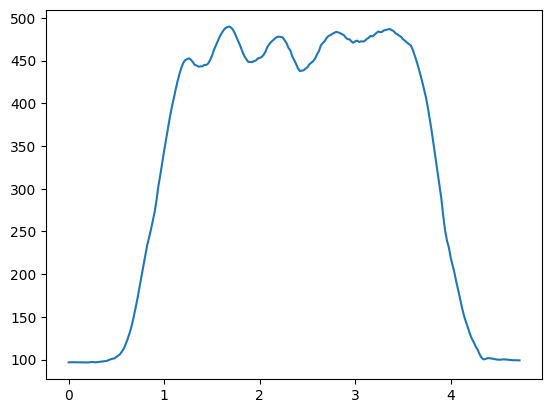

In [11]:
import matplotlib.pyplot as plt

csvfiles = glob.glob(os.path.join(curfolder, 'Sapiens_Output', '*', '*_pose.csv'))
csvsample = csvfiles[0]

TOKEEP = ['nose', 'shoulder', 'elbow', 'hip', 'thumb', 'finger', 'wrist', 'neck']

def flip_axis(df):
    cols = [col for col in df.columns if '_y' in col]
    
    # Identify the maximum value in the first row of the Y_
    maxpoint = max(df.loc[0, cols])

    # Flip all Y_ columns across all rows
    for joint in cols:
        df.loc[:, joint] = maxpoint - df[joint] - 1
            
    return df

def interpolate(df):
    cols = df.columns
    #print(cols)

    # put away time and fileID from cols
    cols = cols.drop(['time_s', 'frame', 'FileID'])

    # loop over the cols and interpolate missing data
    for col in cols:
        df[col] = df[col].interpolate(method='linear', x = df['time_s'], limit=10)
    return df


def clean_and_process_df(file, colstokeep):
    df = pd.read_csv(file)
    name = os.path.basename(file).split('_pose.csv')[0]

    # Get frame and time_s columns
    frames = df['frame']
    time_s = df['time_s']

    # Keep only p1_ columns
    df = df.loc[:, df.columns.str.contains('p1_')]
    
    # Keep only columns that share strings with elements in colstokeep
    df = df.loc[:, df.columns.str.contains('|'.join(colstokeep))]

    # Rename columns to remove p1_ prefix
    df.columns = df.columns.str.replace('p1_', '')

    # Get rid of columns that have '_of_' in (residuals of nose columns that we don't need)
    df = df.loc[:, ~df.columns.str.contains('_of_')]

    # Flip y axis
    df = flip_axis(df)

    # Add name as FileID
    df['FileID'] = name

    # Add time and frames in the beginning
    df['frame'] = frames
    df['time_s'] = time_s

    # Interpolate
    df = interpolate(df)

    return df

sample_proc = clean_and_process_df(csvsample, TOKEEP)
sample_proc.head()

# Plot wrist in y
plt.plot(sample_proc['time_s'], sample_proc['right_wrist_y'])

## Smoothing 

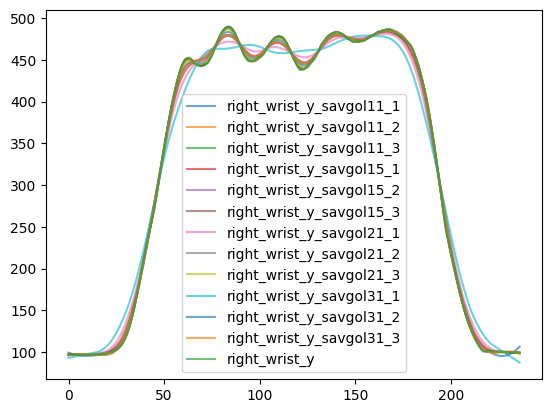

In [12]:
import scipy.signal

# test the different smoothing filter options - smoothing with savitzky-golay filter
x = 'right_wrist_y'
y = 'right_wrist_x'


# list possible window
window = [11, 15, 21, 31]
# list possible orders
order = [1, 2, 3]

# col of interest
samplecol = [y, x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample_proc[col], win, ord)


# make R_Hand_x from df_sample a list
col_x = sample_proc[x].tolist()
col_y = sample_proc[y].tolist()

# load these values into df_smooth as a new column
df_smooth[x] = col_x
df_smooth[y] = col_y

# plot all col_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
plt.show()




In [13]:
import numpy as np, pandas as pd, cv2, glob, os
import scipy.signal
import sys
sys.path.append(os.path.join(curfolder, 'Sapiens'))
from keypoints308 import dataset_info

_ki = dataset_info["keypoint_info"]
KP_NAMES = [_ki[i]["name"] for i in range(len(_ki))]
_name2id = {n: i for i, n in enumerate(KP_NAMES)}
SKELETON_EDGES = [(_name2id[a], _name2id[b], s["color"])
                  for s in dataset_info["skeleton_info"].values()
                  for a, b in [s["link"]]
                  if a in _name2id and b in _name2id]

CONF_THR = 0.3
COMBOS = [(11, 2), (15,2), (21, 2)]      # <-- your three (window, order) choices

def smooth_series(vals, conf, win, order):
    """Mask low-conf -> interpolate -> savgol. vals, conf are 1D arrays over frames."""
    s = pd.Series(vals, dtype=float)
    s[conf < CONF_THR] = np.nan
    s = s.interpolate(limit_direction="both")     # fill gaps so savgol can run
    if s.isna().all():
        return vals                                # nothing usable; leave as-is
    if len(s) <= win:
        return s.to_numpy()                        # too short to filter
    return scipy.signal.savgol_filter(s.to_numpy(), win, order)

def build_smoothed(df, person, win, order):
    """Return dict name -> (x_arr, y_arr) smoothed across all frames for one person."""
    out = {}
    for nm in KP_NAMES:
        cx = df.get(f"{person}_{nm}_x")
        cy = df.get(f"{person}_{nm}_y")
        cc = df.get(f"{person}_{nm}_conf")
        if cx is None:
            continue
        conf = cc.to_numpy() if cc is not None else np.ones(len(df))
        out[nm] = (smooth_series(cx.to_numpy(), conf, win, order),
                   smooth_series(cy.to_numpy(), conf, win, order))
    return out

def draw_skeleton(img, coords_by_name, fi, color=None):
    def pt(nm):
        if nm not in coords_by_name: return None
        x, y = coords_by_name[nm][0][fi], coords_by_name[nm][1][fi]
        return None if (np.isnan(x) or np.isnan(y)) else (int(x), int(y))
    for a, b, c in SKELETON_EDGES:
        pa, pb = pt(KP_NAMES[a]), pt(KP_NAMES[b])
        if pa and pb:
            cv2.line(img, pa, pb, (color or c[::-1]), 2)
    for nm in coords_by_name:
        p = pt(nm)
        if p: cv2.circle(img, p, 3, (color or (0, 255, 0)), -1)
    return img

def render_smoothing_qc(csv_path, video_path, out_dir, person="p1"):
    os.makedirs(out_dir, exist_ok=True)
    df = pd.read_csv(csv_path).sort_values("frame").reset_index(drop=True)
    name = os.path.basename(csv_path).split("_pose.csv")[0]

    # precompute smoothed coords for each combo
    smoothed = {combo: build_smoothed(df, person, *combo) for combo in COMBOS}

    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # one output video per combo
    writers = {combo: cv2.VideoWriter(
                   os.path.join(out_dir, f"{name}_savgol_w{combo[0]}_o{combo[1]}.mp4"),
                   cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
               for combo in COMBOS}

    for fi in range(len(df)):
        vframe = int(df.loc[fi, "frame"])
        cap.set(cv2.CAP_PROP_POS_FRAMES, vframe)
        ok, base = cap.read()
        if not ok: continue
        for combo in COMBOS:
            img = base.copy()
            draw_skeleton(img, smoothed[combo], fi, color=(0, 255, 0))
            cv2.putText(img, f"savgol win={combo[0]} order={combo[1]}", (12, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
            writers[combo].write(img)

    cap.release()
    for w in writers.values(): w.release()
    print("wrote", len(COMBOS), "videos to", out_dir)

# run on one file
filename = sample_proc['FileID'].iloc[0]
csv_path = os.path.join(curfolder, 'Sapiens_Output', filename, filename + '_pose.csv')
video_path = glob.glob(os.path.join(curfolder, "GTST_sampled", filename + "*.mp4"))[0]
render_smoothing_qc(csv_path, video_path, os.path.join(curfolder, "smoothing_qc"))

wrote 3 videos to f:\GtST_FLESH_KinTrajectory\smoothing_qc


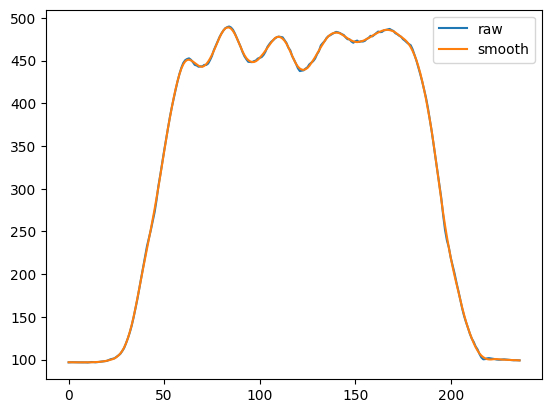

In [14]:
def savgol_smooth(df, window=21, order=2):
    df_smoothed = df.copy()
    colstosmooth = [c for c in df_smoothed.columns if c.endswith('_x') or c.endswith('_y')]
    #print(colstosmooth)
    for col in colstosmooth:
            df_smoothed[col] = scipy.signal.savgol_filter(df[col], window, order)

    return df_smoothed

sample_smooth = savgol_smooth(sample_proc, window=15, order=2)

# plot wrist_y from sample_proc and sample_smooth
plt.plot(sample_proc['right_wrist_y'], label = 'raw')
plt.plot(sample_smooth['right_wrist_y'], label = 'smooth')
plt.legend()
plt.show()

## Normalization

Given the nature of the data, we need to perform three normalization steps

- center all coordinates on mid-torso
- normalize all coordinates by torso length (to account for varying bodies)


In [15]:
def add_midtorso_and_center(
    df,
    l_shoulder_prefix="left_shoulder",
    r_shoulder_prefix="right_shoulder",
    l_hip_prefix="left_hip",
    r_hip_prefix="right_hip"):
    """
    Create mid-torso from shoulders and hips and center all XYZ keypoints on it.

    Expected columns:
      X_<name>, Y_<name>, Z_<name>, visibility_<name>

    Returns a new DataFrame with:
      - X_midTorso, Y_midTorso, Z_midTorso added
      - All X_*, Y_*, Z_* centered on mid-torso
      - visibility_* and time unchanged
    """

    df = df.copy()

    # --- 1. Compute midpoints ---
    df["midtorso_x"] = 0.5 * (df[f"{l_shoulder_prefix}_x"] + df[f"{r_shoulder_prefix}_x"])
    df["midtorso_y"] = 0.5 * (df[f"{l_shoulder_prefix}_y"] + df[f"{r_shoulder_prefix}_y"])

    hips_mid_x = 0.5 * (df[f"{l_hip_prefix}_x"] + df[f"{r_hip_prefix}_x"])
    hips_mid_y = 0.5 * (df[f"{l_hip_prefix}_y"] + df[f"{r_hip_prefix}_y"])

    df["midtorso_x"] = 0.5 * (df["midtorso_x"] + hips_mid_x)
    df["midtorso_y"] = 0.5 * (df["midtorso_y"] + hips_mid_y)

    # --- 2. Center all XYZ columns on mid-torso ---
    x_cols = [c for c in df.columns if c.endswith("_x")]
    y_cols = [c for c in df.columns if c.endswith("_y")]

    # Get rid of columns with finger or thumb in
    x_cols = [c for c in x_cols if "finger" not in c and "thumb" not in c]
    y_cols = [c for c in y_cols if "finger" not in c and "thumb" not in c]

    for c in x_cols:
        df[c] = df[c] - df["midtorso_x"]
    for c in y_cols:
        df[c] = df[c] - df["midtorso_y"]

    return df

def center_fingers_on_wrist(df):

    out = df.copy()
    cols = [c for c in df.columns if "finger" in c or "thumb" in c]

    right_cols = [c for c in cols if c.startswith("right_")]
    left_cols = [c for c in cols if c.startswith("left_")]

    # Get rid of conf columns and wrist
    right_cols = [c for c in right_cols if "conf" not in c]
    left_cols = [c for c in left_cols if "conf" not in c]

    # Center all on wrist
    for c in right_cols:
        axis = c.split('_')[-1]
        out[c] = df[c] - df[f"right_wrist_{axis}"]

    for c in left_cols:
        axis = c.split('_')[-1]
        out[c] = df[c] - df[f"left_wrist_{axis}"]

    return out

    
# usage on sample
sample_norm = add_midtorso_and_center(sample_smooth)
sample_norm = center_fingers_on_wrist(sample_norm)

# check that mid-torso is now at (0,0,0)
print(sample_norm[["midtorso_x", "midtorso_y"]].head())


   midtorso_x  midtorso_y
0         0.0         0.0
1         0.0         0.0
2         0.0         0.0
3         0.0         0.0
4         0.0         0.0


In [16]:
# --- Finger keypoints animated: color = joint category, marker = finger ---
import re
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.lines import Line2D
from IPython.display import HTML

# ---- config ----
df         = sample_norm      # your loaded dataframe
SIDE       = "right"          # "right", "left", or "both"
FRAME_STEP = 1
INVERT_Y   = True             # False if you've already inverted y
SHOW_TRAIL_BG = True
CONNECT    = False            # True = thin line through each finger's joints (reads as finger shapes)

CATEGORY_COLORS = {"third_joint": "#1f77b4", "2": "#2ca02c",
                   "3": "#ff7f0e", "4": "#d62728"}
CATEGORY_LABELS = {"third_joint": "third_joint (MCP)", "2": "finger2 (PIP)",
                   "3": "finger3 (DIP)", "4": "finger4 (TIP)"}
CAT_ORDER = ["third_joint", "2", "3", "4"]           # proximal -> distal
MARKER_POOL = ["o", "s", "^", "D", "v", "P", "X", "*"]

# ---- classify + discover keypoints: (base, finger, category) ----
def canonical_finger(name):
    n = name.lower()
    if "thumb" in n:                 return "thumb"
    if "fore" in n or "index" in n:  return "index"
    if "middle" in n:                return "middle"
    if "ring" in n:                  return "ring"
    if "pink" in n or "little" in n: return "pinky"
    return None

def parse(base):
    m = re.match(r"(right|left)_(.+?)_?(third_joint|\d+)$", base)
    if not m:
        return None
    side, stem, cat = m.groups()
    fng = canonical_finger(stem)          # reject non-finger cols (wrist, face, feet…)
    if fng is None:
        return None
    return side, fng, cat

sides = ["right", "left"] if SIDE == "both" else [SIDE]
kps = []
for c in df.columns:
    if not c.endswith("_x"):
        continue
    p = parse(c[:-2])
    if p and p[0] in sides:
        side, fng, cat = p
        fkey = f"{side}_{fng}" if SIDE == "both" else fng
        kps.append((c[:-2], fkey, cat))

if not kps:
    raise ValueError("No finger keypoints matched — check SIDE / column names.")

data = df.iloc[::FRAME_STEP].reset_index(drop=True)

# assign a marker per finger; group each finger's joints in anatomical order
fingers = sorted({fk for _, fk, _ in kps})
finger_marker = {fk: MARKER_POOL[i % len(MARKER_POOL)] for i, fk in enumerate(fingers)}
by_finger = defaultdict(list)
for base, fk, cat in kps:
    by_finger[fk].append((base, cat))
for fk in by_finger:  # order joints proximal->distal for clean connecting lines
    by_finger[fk].sort(key=lambda bc: CAT_ORDER.index(bc[1]) if bc[1] in CAT_ORDER else 99)

present_cats = [c for c in CAT_ORDER if any(cat == c for _, _, cat in kps)]
print("fingers found:", fingers, "| categories:", present_cats)

# ---- axis limits (fixed so the view doesn't jump) ----
allbases = [b for b, _, _ in kps]
allx = np.concatenate([data[f"{b}_x"].values for b in allbases])
ally = np.concatenate([data[f"{b}_y"].values for b in allbases])
xpad = (np.nanmax(allx) - np.nanmin(allx)) * 0.08 + 1
ypad = (np.nanmax(ally) - np.nanmin(ally)) * 0.08 + 1
xlim = (np.nanmin(allx) - xpad, np.nanmax(allx) + xpad)
ylim = (np.nanmin(ally) - ypad, np.nanmax(ally) + ypad)

# ---- figure ----
fig, ax = plt.subplots(figsize=(7, 7))
ax.set_facecolor("#0e0e12")

if SHOW_TRAIL_BG:
    for base, fk, cat in kps:
        ax.scatter(data[f"{base}_x"], data[f"{base}_y"], s=4,
                   color=CATEGORY_COLORS.get(cat, "gray"), alpha=0.05,
                   zorder=1, linewidths=0)

# one scatter per finger (fixed marker), points colored per category
scatters, lines = {}, {}
for fk, items in by_finger.items():
    colors = [CATEGORY_COLORS.get(cat, "gray") for _, cat in items]
    sc = ax.scatter([np.nan] * len(items), [np.nan] * len(items),
                    marker=finger_marker[fk], s=110, c=colors,
                    edgecolors="white", linewidths=0.7, zorder=3)
    scatters[fk] = (sc, [b for b, _ in items])
    if CONNECT:
        (ln,) = ax.plot([], [], "-", color="white", lw=1, alpha=0.35, zorder=2)
        lines[fk] = (ln, [b for b, _ in items])

ax.set_xlim(*xlim)
ax.set_ylim(*(ylim[::-1] if INVERT_Y else ylim))
ax.set_aspect("equal")
ax.tick_params(colors="gray")
title = ax.set_title("", color="white")

# two legends: color = joint, marker = finger
cat_handles = [Line2D([0], [0], marker="o", linestyle="none",
                      markerfacecolor=CATEGORY_COLORS[c], markeredgecolor="white",
                      markersize=9, label=CATEGORY_LABELS[c]) for c in present_cats]
fg_handles = [Line2D([0], [0], marker=finger_marker[fk], linestyle="none",
                     markerfacecolor="lightgray", markeredgecolor="gray",
                     markersize=9, label=fk) for fk in fingers]
leg1 = ax.legend(handles=cat_handles, loc="upper right", title="joint",
                 framealpha=0.3, facecolor="black", labelcolor="white", fontsize=8)
ax.add_artist(leg1)
ax.legend(handles=fg_handles, loc="upper left", title="finger",
          framealpha=0.3, facecolor="black", labelcolor="white", fontsize=8)

def update(f):
    row = data.iloc[f]
    for fk, (sc, bs) in scatters.items():
        sc.set_offsets([[row[f"{b}_x"], row[f"{b}_y"]] for b in bs])
    if CONNECT:
        for fk, (ln, bs) in lines.items():
            ln.set_data([row[f"{b}_x"] for b in bs], [row[f"{b}_y"] for b in bs])
    title.set_text(f"{SIDE} fingers — frame {f}/{len(data) - 1}")
    return [s for s, _ in scatters.values()] + [title]

anim = FuncAnimation(fig, update, frames=len(data), interval=50, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())

fingers found: ['index', 'middle', 'pinky', 'ring', 'thumb'] | categories: ['third_joint', '2', '3', '4']


Animation size has reached 21011324 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


No trunk length provided, computing from data...
Trunk length used for normalization: 281.24383076971685
Palm length used for normalization: 30.872707564566955


C:\Users\kadava\AppData\Local\Temp\ipykernel_396\3501046267.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["midshoulder_x"] = 0.5 * (df["left_shoulder_x"] + df["right_shoulder_x"])
C:\Users\kadava\AppData\Local\Temp\ipykernel_396\3501046267.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["midshoulder_y"] = 0.5 * (df["left_shoulder_y"] + df["right_shoulder_y"])
C:\Users\kadava\AppData\Local\Temp\ipykernel_396\3501046267.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of callin

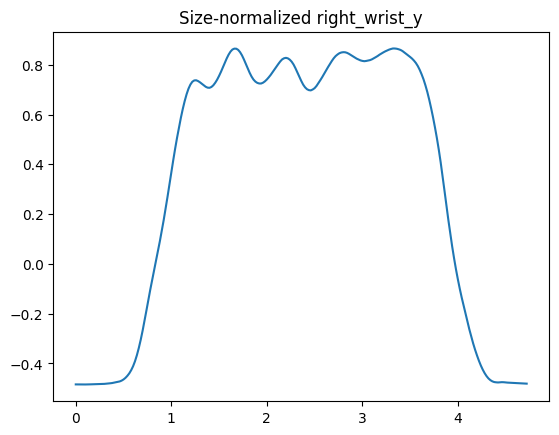

In [17]:
def size_normalize_by_trunk(df, trunk_len=None):

    if trunk_len is None:

        print("No trunk length provided, computing from data...")
    
        # create mid shoulder
        df["midshoulder_x"] = 0.5 * (df["left_shoulder_x"] + df["right_shoulder_x"])
        df["midshoulder_y"] = 0.5 * (df["left_shoulder_y"] + df["right_shoulder_y"])

        # create midhip
        df["midhip_x"] = 0.5 * (df["left_hip_x"] + df["right_hip_x"])
        df["midhip_y"] = 0.5 * (df["left_hip_y"] + df["right_hip_y"])

        # compute trunk length as median distance between mid-shoulder and mid-hip
        dx = df["midshoulder_x"] - df["midhip_x"]
        dy = df["midshoulder_y"] - df["midhip_y"]

        trunk_len = np.median(np.sqrt(dx**2 + dy**2))

    else:
        print(f"Using provided trunk length: {trunk_len}") 

    xy_cols = [c for c in df.columns if c.endswith(("_x", "_y"))]
    xy_cols = [c for c in xy_cols if 'thumb' not in c and 'finger' not in c]
    for c in xy_cols:
        df[c] = df[c] / trunk_len

    return trunk_len, df

def size_normalize_by_palm(df, palm_len = None):

    if palm_len is None:

        scale_left = np.sqrt(
            (df["left_forefinger_third_joint_x"] - df["left_pinky_finger_third_joint_x"])**2 +
            (df["left_forefinger_third_joint_y"] - df["left_pinky_finger_third_joint_y"])**2
        )

        scale_right = np.sqrt(
            (df["right_forefinger_third_joint_x"] - df["right_pinky_finger_third_joint_x"])**2 +
            (df["right_forefinger_third_joint_y"] - df["right_pinky_finger_third_joint_y"])**2
        )

        scale = np.median(np.concatenate([scale_left, scale_right]))
    
    else:
        print(f"Using provided palm length: {palm_len}")
        scale = palm_len

    fingcols = [c for c in df.columns if (('finger' in c) or ('thumb' in c)) and ('conf' not in c)]
    for c in fingcols:
        df[c] = df[c] / scale

    return scale, df

trunk_len, sample_norm = size_normalize_by_trunk(sample_norm)
print(f"Trunk length used for normalization: {trunk_len}")

palm_len, sample_norm = size_normalize_by_palm(sample_norm)
print(f"Palm length used for normalization: {palm_len}")


# plot y_right_wrist again
plt.plot(sample_norm['time_s'], sample_norm['right_wrist_y'])
plt.title('Size-normalized right_wrist_y')
plt.show()



In [28]:
# check if median_trunk_length_per_pcn.csv already exists, if not, create it

if not os.path.exists(os.path.join(curfolder, 'median_body_length_per_pcn.csv')):
    print("median_body_length_per_pcn.csv not found, creating it...")

    error_list = []
    body_len_list = []

    # create txt file
    f = open("error_log.txt", "w")

    #for loop to go through every file in the timeseries folder
    for file in csvfiles:
        print("This is file" + str(file) + "// Count: " + str(csvfiles.index(file)) + " of " + str(len(csvfiles)) + " files in total")

        try:
            # Cleaning
            sample = clean_and_process_df(file, TOKEEP)

            try:
                fileID = sample['FileID'][0]
                #print(fileID)
            except:
                print('FileID not found')
                f.write(f'{fileID} FileID not found\n')
                continue

            sample = savgol_smooth(sample, window=15, order=2)

            # Add mid-torso and center data on it
            sample = add_midtorso_and_center(sample)
            
            # Size-normalize by trunk length
            trunk_len, sample = size_normalize_by_trunk(sample)
            palm_len, sample = size_normalize_by_palm(sample)

            # append trunk_len with fileID to trunk_len_list
            body_len_list.append((fileID, trunk_len, palm_len))
            
        except Exception as e:
            print(f"Error processing {file}: {e}")
            error_list.append(file)
            f.write(f'{file} {e}\n')
            continue
            #break

        #break
        
    f.close()

    # make a df out of trunk_len_list
    body_len_df = pd.DataFrame(body_len_list, columns=['fileID', 'trunk_len', 'palm_len'])

    # make a pcn_ID column by taking fiurst element of fileID split by '_'
    body_len_df['pcn_ID'] = body_len_df['fileID'].apply(lambda x: x.split('_')[0])

    # create a median trunk length per pcn_ID
    median_trunk_len_df = body_len_df.groupby('pcn_ID')['trunk_len'].median().reset_index()

    # create a median palm length per pcn_ID
    median_palm_len_df = body_len_df.groupby('pcn_ID')['palm_len'].median().reset_index()

    # merge 
    median_body_len_df = pd.merge(median_trunk_len_df, median_palm_len_df, on='pcn_ID')

    # save it
    median_body_len_df.to_csv(os.path.join(curfolder, 'median_body_length_per_pcn.csv'), index=False)

    # display
    median_body_len_df.head(10)

else:
    print("median_body_length_per_pcn.csv already exists, loading it...")
    median_body_len_df = pd.read_csv(os.path.join(curfolder, 'median_body_length_per_pcn.csv'))
    median_body_len_df.head(10)



median_body_length_per_pcn.csv not found, creating it...
This is filef:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ADLER\GP01_ADLER_pose.csv// Count: 0 of 1360 files in total
No trunk length provided, computing from data...
This is filef:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ANSTECKEN\GP01_ANSTECKEN_pose.csv// Count: 1 of 1360 files in total
No trunk length provided, computing from data...
This is filef:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BLITZ\GP01_BLITZ_pose.csv// Count: 2 of 1360 files in total
No trunk length provided, computing from data...
This is filef:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BODEN\GP01_BODEN_pose.csv// Count: 3 of 1360 files in total
No trunk length provided, computing from data...
This is filef:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BRIEF\GP01_BRIEF_pose.csv// Count: 4 of 1360 files in total
No trunk length provided, computing from data...
This is filef:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BUERO\GP01_BUERO_pose.csv// Co

In [29]:
median_body_len_df.head(10)

,pcn_ID,trunk_len,palm_len
0,GP01,271.520071,39.485948
1,GP02,282.959010,37.090425
2,GP03,277.612514,35.803668
3,GP04,256.238207,35.104615
4,GP05,242.743345,34.417881
5,GP06,241.093940,24.799107
6,GP08,232.415292,33.303183
7,GP10,269.978350,28.157937
8,GP11,262.248382,35.775822
9,GP14,267.644829,21.972357


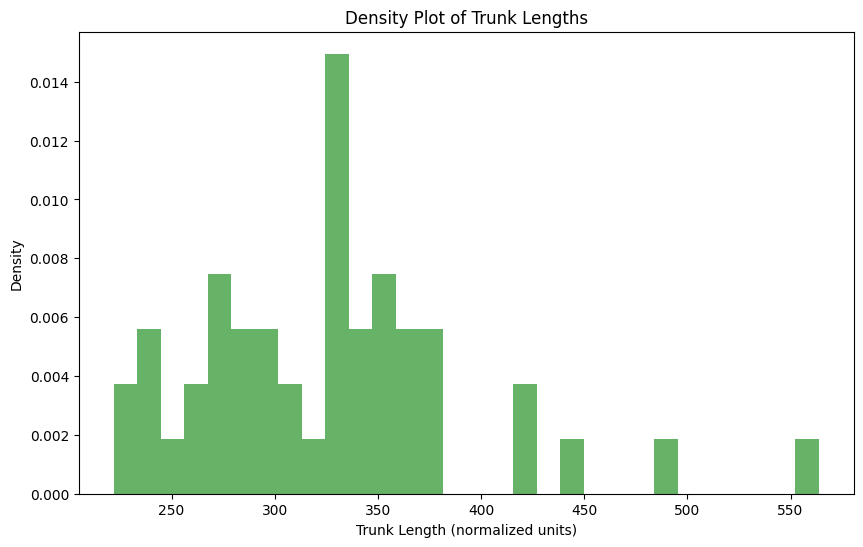

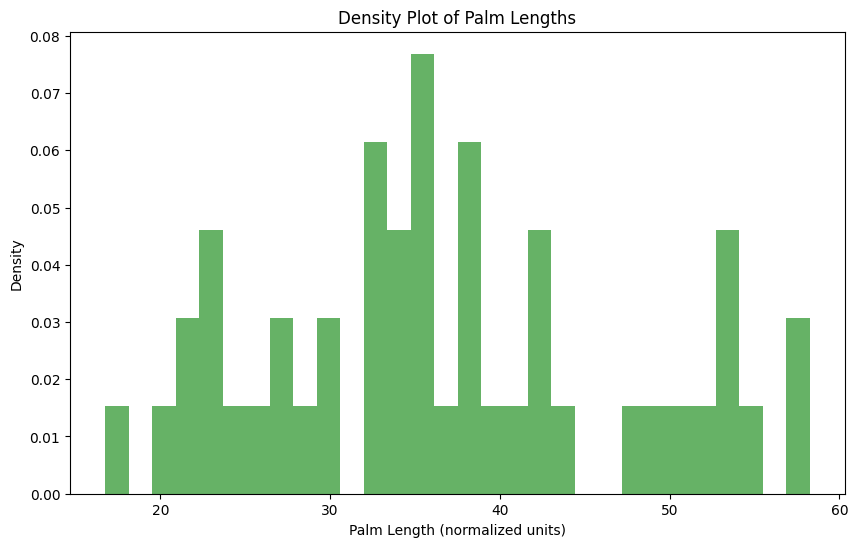

In [30]:
# make a density plot for trunk
plt.figure(figsize=(10, 6))
plt.hist(median_body_len_df['trunk_len'], bins=30, density=True, alpha=0.6, color='g')
plt.title('Density Plot of Trunk Lengths')
plt.xlabel('Trunk Length (normalized units)')
plt.ylabel('Density')
plt.show()

# make a density plot for palm
plt.figure(figsize=(10, 6))
plt.hist(median_body_len_df['palm_len'], bins=30, density=True, alpha=0.6, color='g')
plt.title('Density Plot of Palm Lengths')
plt.xlabel('Palm Length (normalized units)')
plt.ylabel('Density')
plt.show()

## Deriving 

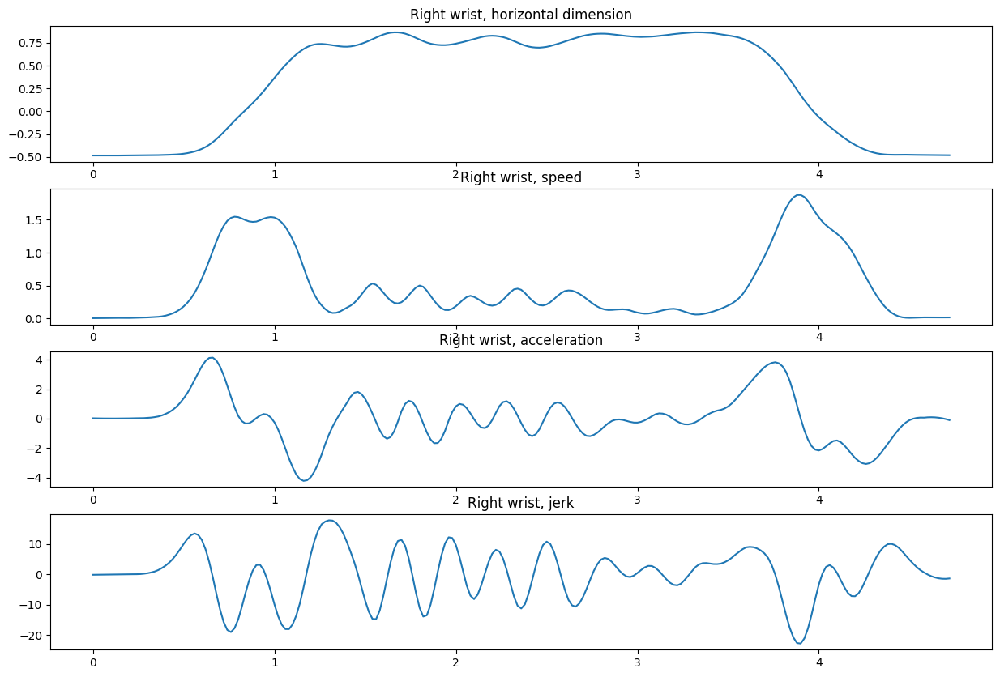

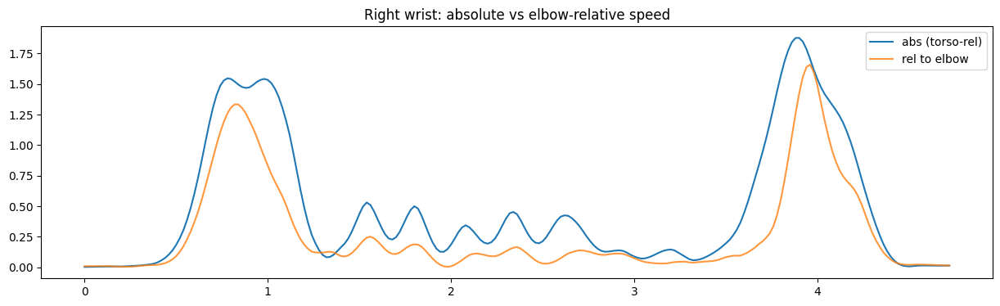

In [31]:
import numpy as np, scipy.signal, pandas as pd

# immediate proximal parent for the arm chain only.
# fingers are NOT here on purpose — palm-centering already makes their _speed
# palm-relative; adding a parent would double-relativize.
PARENT_MAP = {
    "right_wrist": "right_elbow",  "right_elbow": "right_shoulder",
    "left_wrist":  "left_elbow",   "left_elbow":  "left_shoulder",
}

def _smooth(sig, win=15, poly=2):
    win = min(win, len(sig) - (1 - len(sig) % 2))      # keep odd & <= len
    return scipy.signal.savgol_filter(sig, win, poly) if win > poly else sig

def process_derivs(df, sr):
    df = df.reset_index(drop=True)

    bases = sorted({c[:-2] for c in df.columns if c.endswith(("_x", "_y"))})

    speed_dict = {}
    for b in bases:
        if f"{b}_x" not in df.columns or f"{b}_y" not in df.columns:
            continue
        x, y = df[f"{b}_x"].to_numpy(), df[f"{b}_y"].to_numpy()

        # absolute speed (torso-relative for gross kpts, palm-relative for fingers,
        # by virtue of the centering you've already applied)
        speed = np.insert(np.sqrt(np.diff(x)**2 + np.diff(y)**2), 0, 0) * sr
        speed_dict[f"{b}_speed"] = _smooth(speed)

        # parent-relative speed: VECTOR diff first, THEN magnitude
        parent = PARENT_MAP.get(b)
        if parent and f"{parent}_x" in df.columns:
            px, py = df[f"{parent}_x"].to_numpy(), df[f"{parent}_y"].to_numpy()
            rdx = np.diff(x) - np.diff(px)          # <-- the fix: subtract as vectors
            rdy = np.diff(y) - np.diff(py)
            relspeed = np.insert(np.sqrt(rdx**2 + rdy**2), 0, 0) * sr
            speed_dict[f"{b}_relspeed"] = _smooth(relspeed)

    df = pd.concat([df, pd.DataFrame(speed_dict, index=df.index)], axis=1)

    # acceleration = d/dt of every speed/relspeed column (subtract ONCE, then only differentiate)
    accel = {}
    for col in [c for c in df.columns if c.endswith("speed")]:
        a = np.insert(np.diff(df[col].to_numpy()), 0, 0) * sr
        accel[col.replace("speed", "acc")] = _smooth(a)
    df = pd.concat([df, pd.DataFrame(accel, index=df.index)], axis=1)

    # jerk = d/dt of every acc/relacc column
    jerk = {}
    for col in [c for c in df.columns if c.endswith("acc")]:
        j = np.insert(np.diff(df[col].to_numpy()), 0, 0) * sr
        jerk[col.replace("acc", "jerk")] = _smooth(j)
    df = pd.concat([df, pd.DataFrame(jerk, index=df.index)], axis=1)

    return df


sr = round(len(sample_norm) / (sample_norm['time_s'].iloc[-1] - sample_norm['time_s'].iloc[0]), 0)
sample_der = process_derivs(sample_norm, sr=30.0)

# plot RIGHT_WRIST_y, speed, accel and jerk in grid of 4 subplots
plt.figure(figsize=(15, 10))
plt.subplot(4, 1, 1)
plt.plot(sample_der['time_s'], sample_der['right_wrist_y'])
plt.title('Right wrist, horizontal dimension')
plt.subplot(4, 1, 2)
plt.plot(sample_der['time_s'], sample_der['right_wrist_speed'])
plt.title('Right wrist, speed')
plt.subplot(4,1,3)
plt.plot(sample_der['time_s'], sample_der['right_wrist_acc'])
plt.title('Right wrist, acceleration')
plt.subplot(4,1,4)
plt.plot(sample_der['time_s'], sample_der['right_wrist_jerk'])
plt.title('Right wrist, jerk')    
plt.show()

# compare absolute (torso-relative) vs parent-relative wrist speed — see if the fix bites
plt.figure(figsize=(15, 4))
plt.plot(sample_der['time_s'], sample_der['right_wrist_speed'],    label='abs (torso-rel)')
plt.plot(sample_der['time_s'], sample_der['right_wrist_relspeed'], label='rel to elbow', alpha=0.8)
plt.legend(); plt.title('Right wrist: absolute vs elbow-relative speed'); plt.show()

In [32]:
sample_der.head()

,nose_x,nose_y,nose_conf,left_shoulder_x,left_shoulder_y,left_shoulder_conf,right_shoulder_x,right_shoulder_y,right_shoulder_conf,left_elbow_x,...,right_ring_finger3_jerk,right_ring_finger4_jerk,right_ring_finger_third_joint_jerk,right_shoulder_jerk,right_thumb2_jerk,right_thumb3_jerk,right_thumb4_jerk,right_thumb_third_joint_jerk,right_wrist_jerk,right_wrist_reljerk
0,-0.094696,0.842837,0.995890,0.363269,0.477875,0.906768,-0.363384,0.473822,0.894053,0.516706,...,-0.965909,-0.584110,-1.595093,-0.040025,-0.077723,0.463037,1.596969,-1.119497,-0.114203,-0.276349
1,-0.093718,0.842258,0.994249,0.363583,0.477481,0.906669,-0.363164,0.474047,0.894525,0.516572,...,-0.084790,-0.376847,-0.907829,-0.058130,-0.371694,0.025813,1.542714,-1.321038,-0.095362,-0.249734
2,-0.092756,0.841843,0.993359,0.363874,0.477137,0.905404,-0.362962,0.474254,0.893699,0.516469,...,0.630408,-0.205163,-0.279505,-0.071071,-0.574807,-0.305706,1.471255,-1.437946,-0.076323,-0.219412
3,-0.091812,0.841593,0.992332,0.364143,0.476844,0.906424,-0.362777,0.474444,0.895529,0.516397,...,1.179684,-0.069059,0.289879,-0.078850,-0.687064,-0.531519,1.382591,-1.470221,-0.057085,-0.185381
4,-0.090886,0.841507,0.991208,0.364388,0.476601,0.906283,-0.362609,0.474618,0.895539,0.516356,...,1.563040,0.031465,0.800322,-0.081466,-0.708464,-0.651627,1.276723,-1.417861,-0.037649,-0.147644


In [41]:
def resample_to_fps(df, target_fps=30, time_col='time_s', tol=2.0, min_frames=16):
    """Resample all _x/_y coordinate columns onto a uniform target_fps grid.
    No-ops if the file is already ~target_fps, or if the clip would be too short
    to smooth afterwards. Returns (df_out, was_resampled)."""
    fid = df['FileID'].iloc[0] if 'FileID' in df.columns else None
    t_old = df[time_col].to_numpy(float)
    dur = t_old[-1] - t_old[0]
    if dur <= 0:
        return df, False
    cur_fps = (len(df) - 1) / dur

    if abs(cur_fps - target_fps) <= tol:            # already fine -> leave as-is
        return df, False

    t_new = np.arange(t_old[0], t_old[-1] + 1e-9, 1.0 / target_fps)
    if len(t_new) < min_frames:                     # too short after downsampling
        print(f"  ! {fid}: only {len(t_new)} frames at {target_fps}fps; kept native {cur_fps:.0f}fps")
        return df, False

    coord_cols = [c for c in df.columns if c.endswith('_x') or c.endswith('_y')]
    out = {time_col: t_new, 'frame': np.arange(len(t_new))}
    for c in coord_cols:
        y = df[c].to_numpy(float)
        m = ~np.isnan(y)
        out[c] = np.interp(t_new, t_old[m], y[m]) if m.sum() >= 2 else np.full(len(t_new), np.nan)
    out_df = pd.DataFrame(out)
    if fid is not None:
        out_df['FileID'] = fid
    return out_df, True

# Full loop body+hand

In [42]:
import warnings
warnings.filterwarnings('ignore')

TOKEEP = ['nose', 'shoulder', 'elbow', 'hip', 'thumb', 'finger', 'wrist', 'neck']
TARGET_FPS = 30
errors = []
resampled_files = []

median_bodylen = pd.read_csv('median_body_length_per_pcn.csv')

for csv in csvfiles:
    print('Processing: ', csv)

    try:
        df = clean_and_process_df(csv, TOKEEP)          # clean (flip + interpolate)
        df = df.loc[:, ~df.columns.str.contains('_conf')]
    except Exception as e:
        print('Error in processing: ', csv)
        errors.append(csv)
        continue

    # --- resample to a common frame rate BEFORE smoothing/derivatives ---
    df, was_resampled = resample_to_fps(df, target_fps=TARGET_FPS)
    if was_resampled:
        resampled_files.append(df['FileID'].iloc[0])

    df = savgol_smooth(df, window=15, order=2)           # smooth (windows now consistent across files)
    df = add_midtorso_and_center(df)                     # center
    df = center_fingers_on_wrist(df)

    pcn_ID = df['FileID'].iloc[0].split('_')[0]
    trunklen = median_bodylen[median_bodylen['pcn_ID'] == pcn_ID]['trunk_len'].iloc[0]
    palmlen  = median_bodylen[median_bodylen['pcn_ID'] == pcn_ID]['palm_len'].iloc[0]
    trunklen, df = size_normalize_by_trunk(df, trunk_len=trunklen)   # normalize
    palmlen,  df = size_normalize_by_palm(df,  palm_len=palmlen)

    sr = round(len(df) / (df['time_s'].iloc[-1] - df['time_s'].iloc[0]), 0)   # ~TARGET_FPS now
    print('Sampling rate: ', sr)
    df = process_derivs(df, sr=sr)                        # derivations

    # Aggregates (parent-relative arm chain)
    df['arm_total_speed'] = np.sqrt(
        df['left_shoulder_speed']**2  + df['right_shoulder_speed']**2 +
        df['left_elbow_relspeed']**2  + df['right_elbow_relspeed']**2 +
        df['left_wrist_relspeed']**2  + df['right_wrist_relspeed']**2)

    df['arm_total_acc'] = np.sqrt(
        df['left_shoulder_acc']**2  + df['right_shoulder_acc']**2 +
        df['left_elbow_relacc']**2  + df['right_elbow_relacc']**2 +
        df['left_wrist_relacc']**2  + df['right_wrist_relacc']**2)

    df['arm_total_jerk'] = np.sqrt(
        df['left_shoulder_jerk']**2  + df['right_shoulder_jerk']**2 +
        df['left_elbow_reljerk']**2  + df['right_elbow_reljerk']**2 +
        df['left_wrist_reljerk']**2  + df['right_wrist_reljerk']**2)

    name = df['FileID'][0] + '_kinematics.csv'
    df.to_csv(os.path.join(curfolder, 'Sapiens_Processed', name), index=False)

print(f"\nDone. Resampled {len(resampled_files)} files to {TARGET_FPS} fps; {len(errors)} errors.")

Processing:  f:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ADLER\GP01_ADLER_pose.csv
Using provided trunk length: 271.52007105075825
Using provided palm length: 39.48594824868144
Sampling rate:  30.0
Processing:  f:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_ANSTECKEN\GP01_ANSTECKEN_pose.csv
Using provided trunk length: 271.52007105075825
Using provided palm length: 39.48594824868144
Sampling rate:  30.0
Processing:  f:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BLITZ\GP01_BLITZ_pose.csv
Using provided trunk length: 271.52007105075825
Using provided palm length: 39.48594824868144
Sampling rate:  30.0
Processing:  f:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BODEN\GP01_BODEN_pose.csv
Using provided trunk length: 271.52007105075825
Using provided palm length: 39.48594824868144
Sampling rate:  30.0
Processing:  f:\GtST_FLESH_KinTrajectory\Sapiens_Output\GP01_BRIEF\GP01_BRIEF_pose.csv
Using provided trunk length: 271.52007105075825
Using provided palm length: 39.48594824868144
Sam

In [48]:
df

,time_s,frame,nose_x,nose_y,left_shoulder_x,left_shoulder_y,right_shoulder_x,right_shoulder_y,left_elbow_x,left_elbow_y,...,left_pinky_finger2_y,left_pinky_finger_third_joint_x,left_pinky_finger_third_joint_y,left_wrist_x,left_wrist_y,neck_x,neck_y,FileID,midtorso_x,midtorso_y
0,0.000000,0,-0.000293,0.821266,0.311628,0.516089,-0.310016,0.484849,0.413301,-0.008639,...,4.090705,11.153875,4.254558,0.249000,-0.398026,-0.005356,0.580295,ViCom_9_C_BIRTH,0.0,0.0
1,0.033333,1,-0.000357,0.825580,0.312184,0.515283,-0.310478,0.484911,0.422803,-0.002445,...,3.984943,11.347077,4.163462,0.257853,-0.358377,-0.005416,0.583724,ViCom_9_C_BIRTH,0.0,0.0
2,0.066667,2,-0.000474,0.829443,0.312709,0.514619,-0.310976,0.484995,0.432319,0.003807,...,3.897933,11.521610,4.088655,0.266032,-0.320512,-0.005498,0.586751,ViCom_9_C_BIRTH,0.0,0.0
3,0.100000,3,-0.000643,0.832854,0.313201,0.514098,-0.311512,0.485102,0.441850,0.010119,...,3.829676,11.677473,4.030137,0.273538,-0.284429,-0.005603,0.589377,ViCom_9_C_BIRTH,0.0,0.0
4,0.133333,4,-0.000866,0.835814,0.313662,0.513719,-0.312084,0.485231,0.451395,0.016489,...,3.780172,11.814666,3.987909,0.280369,-0.250130,-0.005729,0.591601,ViCom_9_C_BIRTH,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,1.933333,58,-0.001110,0.832359,0.313646,0.515523,-0.310765,0.486739,0.438613,0.016639,...,3.943038,11.344963,4.265085,0.256342,-0.301826,-0.006568,0.593206,ViCom_9_C_BIRTH,0.0,0.0
59,1.966667,59,-0.002753,0.832438,0.313521,0.515005,-0.310765,0.487255,0.434875,0.015011,...,3.933654,11.336220,4.255391,0.257754,-0.306604,-0.006618,0.593300,ViCom_9_C_BIRTH,0.0,0.0
60,2.000000,60,-0.004632,0.832687,0.313379,0.514299,-0.310720,0.487795,0.431008,0.013253,...,3.918292,11.330511,4.240326,0.259479,-0.311095,-0.006649,0.593454,ViCom_9_C_BIRTH,0.0,0.0
61,2.033333,61,-0.006747,0.833106,0.313219,0.513406,-0.310630,0.488358,0.427012,0.011364,...,3.896952,11.327837,4.219889,0.261518,-0.315300,-0.006661,0.593668,ViCom_9_C_BIRTH,0.0,0.0


# Finger distances

In [43]:
import re, glob, os
import numpy as np, pandas as pd, scipy.signal

# ---------- finger classification (handles Sapiens' inconsistent names) ----------
def canonical_finger(name):
    n = name.lower()
    if "thumb" in n:                 return "thumb"
    if "fore" in n or "index" in n:  return "index"
    if "middle" in n:                return "middle"
    if "ring" in n:                  return "ring"
    if "pink" in n or "little" in n: return "pinky"
    return None

# ---------- build MediaPipe-compatible number -> Sapiens stem (no side prefix) ----------
def build_handmap(df, side="right", verbose=True):
    FINGER_BASE = {"index": 5, "middle": 9, "ring": 13, "pinky": 17}
    CAT_OFFSET  = {"third_joint": 0, "2": 1, "3": 2, "4": 3}   # MCP,PIP,DIP,TIP
    THUMB_NUM   = {"third_joint": 1, "2": 2, "3": 3, "4": 4}   # CMC,MCP,IP,TIP -- VERIFY
    handmap = {}

    # wrist (number 0) -- adjust candidate names if yours differ
    for cand in [f"{side}_wrist", f"{side}_hand_root", f"{side}_hand"]:
        if f"{cand}_x" in df.columns:
            handmap[0] = cand[len(side) + 1:]
            break

    for c in df.columns:
        if not (c.startswith(f"{side}_") and c.endswith("_x")):
            continue
        stem = c[len(side) + 1:-2]                 # e.g. "ring_finger4"
        fng  = canonical_finger(stem)
        m    = re.search(r"(third_joint|\d+)$", stem)
        if fng is None or m is None:
            continue
        cat = m.group(1)
        if fng == "thumb" and cat in THUMB_NUM:
            handmap[THUMB_NUM[cat]] = stem
        elif fng in FINGER_BASE and cat in CAT_OFFSET:
            handmap[FINGER_BASE[fng] + CAT_OFFSET[cat]] = stem

    if verbose:
        missing = set(range(21)) - set(handmap)
        for n in sorted(handmap):
            print(f"{n:2d} -> {side}_{handmap[n]}")
        if missing:
            print(f"⚠️ missing keypoint numbers: {sorted(missing)} "
                  f"-- distances using these will fail; check naming.")
    return handmap

# ---------- 2D inter-joint distance, both hands ----------
def gethandjointdistance(sample, handmap, j1, j2):
    out = []
    for side in ["left", "right"]:
        def coords(j):
            if j == 0:                       # wrist = finger-frame origin
                z = np.zeros(len(sample))
                return z, z
            b = handmap[j]
            return (sample[f"{side}_{b}_x"].to_numpy(),
                    sample[f"{side}_{b}_y"].to_numpy())
        x1, y1 = coords(j1); x2, y2 = coords(j2)
        dx, dy = x1 - x2, y1 - y2
        out += [dx, dy, np.sqrt(dx**2 + dy**2)]
    return out

# ---------- speed / accel / jerk on the scalar magnitude columns ----------
def derive_speed_accel_jerk(df, sr):
    def smooth(sig):
        try:    return scipy.signal.savgol_filter(sig, 15, 3)
        except ValueError: return scipy.signal.savgol_filter(sig, 7, 3)
    for col in df.columns.drop(["time_s", "FileID"]):
        if col.endswith(("_x", "_y")):
            continue
        sp = np.abs(np.insert(np.diff(df[col]), 0, 0))
        sp = smooth(sp) * sr                # per-second
        df[col + "_speed"] = sp
        ac = smooth(np.insert(np.diff(sp), 0, 0)) * sr
        df[col + "_acc"] = ac      
        df[col + "_jerk"] = smooth(np.insert(np.diff(ac), 0, 0)) * sr
    return df

outputfolder = os.path.join(curfolder, 'Sapiens_Processed')

# ---------- driver ----------
DISTANCE_PAIRS = [
    (4,2),(4,1),(3,1),(4,17),(2,0),(3,0),(4,0),        # thumb
    (8,6),(7,5),(8,5),(6,0),(7,0),(8,0),               # index
    (12,10),(11,9),(12,9),(10,0),(11,0),(12,0),        # middle
    (16,14),(15,13),(16,13),(14,0),(15,0),(16,0),      # ring
    (20,18),(19,17),(20,17),(18,0),(19,0),(20,0),      # pinky
    (4,8),(8,12),(12,16),(16,20),                      # adjacent fingertip spans
]

hand_distances_error = []
processed_files = glob.glob(os.path.join(outputfolder, "*kinematics*.csv"))

for file in processed_files:
    print("working on", file)
    fname = os.path.basename(file)
    df = pd.read_csv(file)
    try:
        fileID = df["FileID"][0]
    except KeyError:
        hand_distances_error.append(("missing FileID column", file)); continue

    sr = round(len(df) / (df['time_s'].iloc[-1] - df['time_s'].iloc[0]), 0) # calculate sample rate

    df = df.drop([c for c in df.columns
                  if any(k in c for k in ("speed","velocity","acc","jerk"))], axis=1)

    handmap = build_handmap(df, side="right", verbose=False)   # stems shared across sides

    try:
        records = {"FileID": fileID, "time_s": df["time_s"]}
        for j1, j2 in DISTANCE_PAIRS:
            dx_l, dy_l, d_l, dx_r, dy_r, d_r = gethandjointdistance(df, handmap, j1, j2)
            for pref, dx, dy, d in [("l", dx_l, dy_l, d_l), ("r", dx_r, dy_r, d_r)]:
                k = f"{pref}{j1}_{j2}"
                records[f"{k}_x"], records[f"{k}_y"], records[k] = dx, dy, d
        df_distances = pd.DataFrame(records)
    except KeyError as e:
        print(f"⚠️ Distances error {fileID}: {e}")
        hand_distances_error.append(("error in calculating distances", file)); continue

    try:
        df_distances = derive_speed_accel_jerk(df_distances, sr)
    except Exception as e:
        print(f"⚠️ Speed/accel/jerk error {fileID}: {e}")
        hand_distances_error.append(("error in speed/accel/jerk", file)); continue

    out_path = os.path.join(outputfolder, fname.replace("kinematics", "hand_distances"))
    df_distances.to_csv(out_path, index=False)
    #break

working on f:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_ADLER_kinematics.csv
working on f:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_ANSTECKEN_kinematics.csv
working on f:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_BLITZ_kinematics.csv
working on f:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_BODEN_kinematics.csv
working on f:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_BRIEF_kinematics.csv
working on f:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_BUERO_kinematics.csv
working on f:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_ENTSCHULDIGEN_kinematics.csv
working on f:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_GEIGE_kinematics.csv
working on f:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_GIRAFFE_kinematics.csv
working on f:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_GOTT_kinematics.csv
working on f:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_HEMD_kinematics.csv
working on f:\GtST_FLESH_KinTrajectory\Sapiens_Processed\GP01_KLOPFEN_kinem

# Visualize

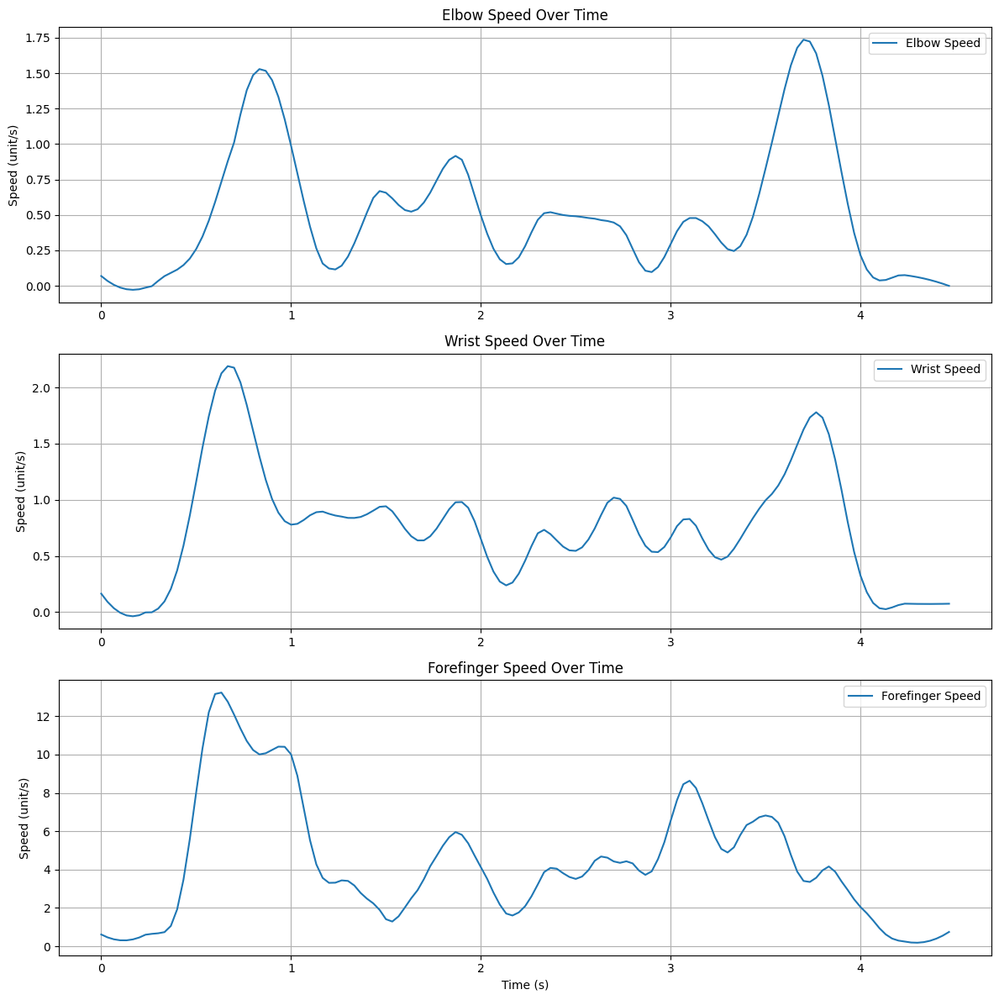

In [44]:
processedfiles = glob.glob(os.path.join(outputfolder, "*kinematics*.csv"))
sample = processedfiles[30]


import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv(sample)

fig, axs = plt.subplots(3, 1, figsize=(12, 12))
axs[0].plot(data['time_s'], data['right_elbow_relspeed'], label='Elbow Speed')
axs[0].set_ylabel('Speed (unit/s)')
axs[0].set_title('Elbow Speed Over Time')
axs[0].legend()
axs[0].grid(True)

axs[1].plot(data['time_s'], data['right_wrist_relspeed'], label='Wrist Speed')
axs[1].set_ylabel('Speed (unit/s)')
axs[1].set_title('Wrist Speed Over Time')
axs[1].legend()
axs[1].grid(True)

axs[2].plot(data['time_s'], data['right_forefinger4_speed'], label='Forefinger Speed')
axs[2].set_xlabel('Time (s)')
axs[2].set_ylabel('Speed (unit/s)')
axs[2].set_title('Forefinger Speed Over Time')
axs[2].legend()
axs[2].grid(True)

plt.tight_layout()
plt.show()

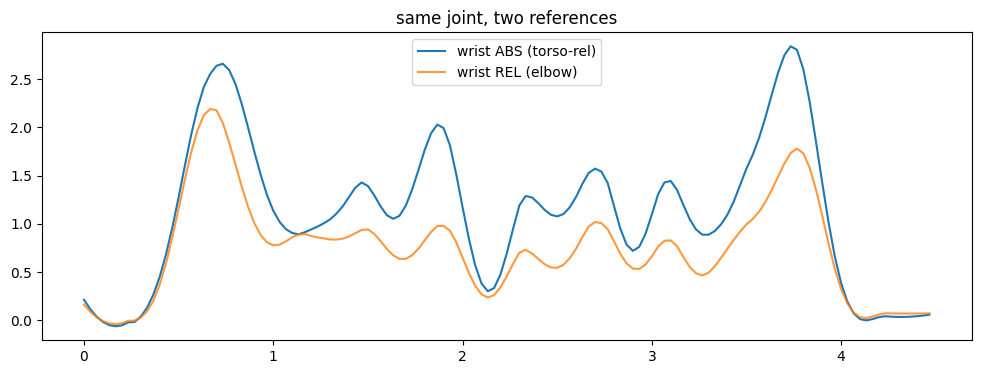

In [45]:
data.FileID

plt.figure(figsize=(12,4))
plt.plot(data.time_s, data.right_wrist_speed,    label='wrist ABS (torso-rel)')
plt.plot(data.time_s, data.right_wrist_relspeed, label='wrist REL (elbow)', alpha=.8)
plt.legend(); plt.title('same joint, two references'); plt.show()


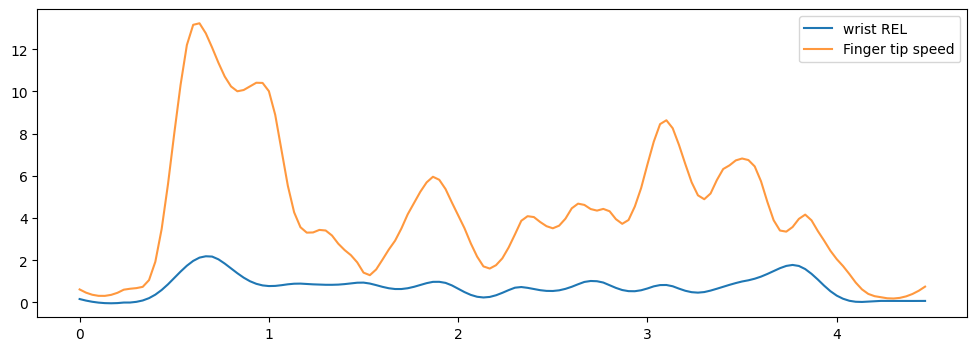

In [46]:
data.FileID

plt.figure(figsize=(12,4))
plt.plot(data.time_s, data.right_wrist_relspeed,    label='wrist REL')
plt.plot(data.time_s, data.right_forefinger4_speed, label='Finger tip speed', alpha=.8)
plt.legend(); plt.title(''); plt.show()


In [47]:
import numpy as np
sig = {
    "elbow_rel":  data.right_elbow_relspeed,
    "wrist_rel":  data.right_wrist_relspeed,
    "finger_tip": data.right_forefinger4_speed,
    "finger_artic": np.hypot(  # index tip relative to its own MCP = pure finger flexion
        data.right_forefinger4_x - data.right_forefinger_third_joint_x,
        data.right_forefinger4_y - data.right_forefinger_third_joint_y).diff().abs(),
}
print(pd.DataFrame(sig).corr().round(2))

              elbow_rel  wrist_rel  finger_tip  finger_artic
elbow_rel          1.00       0.77        0.56          0.47
wrist_rel          0.77       1.00        0.75          0.50
finger_tip         0.56       0.75        1.00          0.66
finger_artic       0.47       0.50        0.66          1.00
